In [13]:
# Run this cell. It imports the libraries and loads the data file you upload.
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

FILE = "Date_Fruit_Datasets.xlsx"

def find_data_file():
    # 1) the Excel file is already here
    hits = glob.glob(f"**/{FILE}", recursive=True)
    if hits:
        return hits[0]
    # 2) a zip was uploaded: unzip it
    for z in glob.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall("date_data")
    hits = glob.glob(f"**/{FILE}", recursive=True)
    return hits[0] if hits else None

path = find_data_file()
if path is None:
    from google.colab import files
    print("Please upload archive.zip (or Date_Fruit_Datasets.xlsx) from Kaggle")
    files.upload()
    path = find_data_file()

print("Data file found:", path)
np.random.seed(42)

Data file found: date_data/Date_Fruit_Datasets/Date_Fruit_Datasets.xlsx


### **`Step 1 · Understand the mission 🎯`**

- The **input** `X` of our model is: the measurement/features of each data (size,shape,color)
- The **output** `y` of our model is: The specific variety/class of the date out of the 7 varieties.
- Is this **regression** or **classification**? Why?classification,because we are predicting discrate category  labels.
- Is it **binary** or **multiclass**? multiclass.
- What does Abu Fahad gain if the model works? What does he lose if it makes mistakes?


*   **Gain:** Fast, accurate, and automated sorting, saving time and labor while keeping customers happy (avoiding angry customers receiving mixed boxes)


*   **Loss:** Mixed premium boxes, unhappy customers, complaints, and loss of business reputation






### **Step 2 · Open the evidence 🗂️**

In [14]:
df = pd.read_excel(path)
print("Data shape:", df.shape)
print("Data columns:", df.columns)


df.head()

Data shape: (898, 35)
Data columns: Index(['AREA', 'PERIMETER', 'MAJOR_AXIS', 'MINOR_AXIS', 'ECCENTRICITY',
       'EQDIASQ', 'SOLIDITY', 'CONVEX_AREA', 'EXTENT', 'ASPECT_RATIO',
       'ROUNDNESS', 'COMPACTNESS', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2',
       'SHAPEFACTOR_3', 'SHAPEFACTOR_4', 'MeanRR', 'MeanRG', 'MeanRB',
       'StdDevRR', 'StdDevRG', 'StdDevRB', 'SkewRR', 'SkewRG', 'SkewRB',
       'KurtosisRR', 'KurtosisRG', 'KurtosisRB', 'EntropyRR', 'EntropyRG',
       'EntropyRB', 'ALLdaub4RR', 'ALLdaub4RG', 'ALLdaub4RB', 'Class'],
      dtype='object')


,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [15]:
# ✅ Check
assert df.shape == (898, 35), "df should have 898 rows and 35 columns. Did you read the right file?"
print("✅ Evidence loaded:", df.shape[0], "dates,", df.shape[1] - 1, "measurements + 1 label column")

✅ Evidence loaded: 898 dates, 34 measurements + 1 label column


Class
DOKOL     204
SAFAVI    199
ROTANA    166
DEGLET     98
SOGAY      94
IRAQI      72
BERHI      65
Name: count, dtype: int64


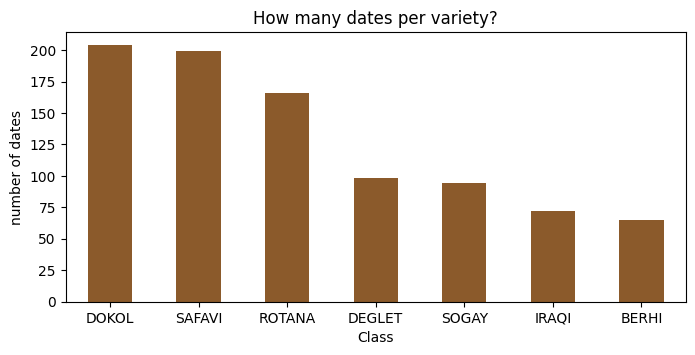

In [16]:
counts = df['Class'].value_counts()
print(counts)

counts.plot(kind="bar", color="#8B5A2B", figsize=(8, 3.5), title="How many dates per variety?")
plt.ylabel("number of dates"); plt.xticks(rotation=0); plt.show()

**Fewest dates:** BERHI (65 dates).

**Most dates:** DOKOL (204 dates).

Why imbalance could be a problem: This imbalance can cause the model to be biased toward the majority classes (like DOKOL) and perform poorly on minority classes (like BERHI) because it learns less from them.

### **Step 3 · Know your clues 🔎**

In [17]:
SIZE   = ["AREA", "PERIMETER", "MAJOR_AXIS", "MINOR_AXIS", "EQDIASQ", "CONVEX_AREA"]
SHAPE  = ["ECCENTRICITY", "SOLIDITY", "EXTENT", "ASPECT_RATIO", "ROUNDNESS", "COMPACTNESS",
          "SHAPEFACTOR_1", "SHAPEFACTOR_2", "SHAPEFACTOR_3", "SHAPEFACTOR_4"]
COLOUR = [c for c in df.columns if c not in SIZE + SHAPE + ["Class"]]
print(len(SIZE), "size +", len(SHAPE), "shape +", len(COLOUR), "colour =", len(SIZE + SHAPE + COLOUR), "clues")

VARIETIES = sorted(df["Class"].unique())
PALETTE = dict(zip(VARIETIES, ["#2E86AB", "#E67E22", "#8E44AD", "#27AE60", "#C0392B", "#3E2723", "#7F8C8D"]))

def scatter_two_clues(data, x_col, y_col):
    plt.figure(figsize=(7, 5))
    for v in VARIETIES:
        part = data[data["Class"] == v]
        plt.scatter(part[x_col], part[y_col], s=14, alpha=0.7, label=v, color=PALETTE[v])
    plt.xlabel(x_col); plt.ylabel(y_col); plt.legend(markerscale=2, fontsize=8)
    plt.title(f"Each dot is one date: {x_col} vs {y_col}"); plt.show()

6 size + 10 shape + 18 colour = 34 clues


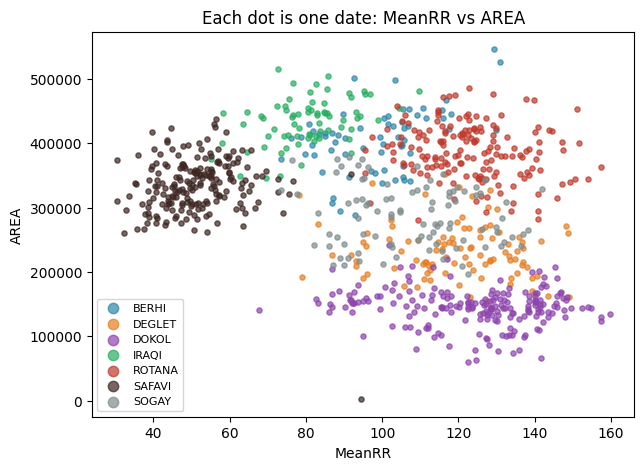

In [18]:
x_col = "MeanRR"  # (average redness)
y_col = "AREA"    # (size)
scatter_two_clues(df, x_col, y_col)

- Clear groups: Some varieties form distinct clusters based on their size and color (like DOKOL or SAFAVI).
- Overlapping varieties: Other varieties overlap and are hard to separate clearly using just these two clues.
- Strange dot: Yes, there might be an outlier or a strange dot located far away from the main clusters that does not look like a normal date measurement.

### **Step 4 · Prepare the evidence**

In [19]:
n_missing = df.isna().sum().sum()

n_duplicates = df.duplicated().sum()
print("Missing values:", n_missing, "| Duplicated rows:", n_duplicates)

Missing values: 0 | Duplicated rows: 0


### **4.2 🕵️ The suspicious date**

In [20]:
df[SIZE + ["ASPECT_RATIO"]].describe().loc[["min", "50%", "max"]].round(1)

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,EQDIASQ,CONVEX_AREA,ASPECT_RATIO
min,1987.0,911.8,336.7,2.3,50.3,2257.0,1.1
50%,319833.0,2196.3,791.4,495.1,638.1,327207.0,1.5
max,546063.0,2812.0,1222.7,766.5,833.8,552598.0,535.5


In [21]:
suspicious = df[df["MINOR_AXIS"]< 100]
suspicious[["AREA", "MAJOR_AXIS", "MINOR_AXIS", "ASPECT_RATIO", "Class"]]

,AREA,MAJOR_AXIS,MINOR_AXIS,ASPECT_RATIO,Class
615,1987,1222.723,2.2832,535.5257,SAFAVI


- Can a real date be like this?: No, a normal date fruit cannot be about 900 pixels long and only 2 pixels wide.
- What probably happened?: This is likely a measurement error, a bad camera capture, or an outlier/noise in the data.
- What should we do with this row?: We should filter it out (remove it) because it is corrupted data that could confuse our machine learning model.

In [22]:
df = df[df["MINOR_AXIS"]>=100]
print(df.shape)

(897, 35)


### 4.3 Split the evidence: training set and test set

In [23]:
X = df.drop(columns="Class")
y = df["Class"]

# TODO: split into train (80%) and test (20%), with stratify=y and random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (717, 34) | Test: (180, 34)


In [24]:
X_train[["AREA", "ECCENTRICITY", "MeanRR"]].agg(["min", "max"]).round(2)

,AREA,ECCENTRICITY,MeanRR
min,63328,0.38,30.38
max,546063,0.90,159.65


Large features (like AREA) will dominate small features and slow down gradient descent. Scaling ensures all features contribute fairly.

---
# Step 5 · The lazy detective (baseline) 😴

In [25]:

lazy = DummyClassifier (strategy="most_frequent").fit(X_train, y_train)

lazy_acc = accuracy_score(y_test, lazy.predict(X_test))
print(f"Lazy detective accuracy: {lazy_acc:.1%}")

Lazy detective accuracy: 22.8%


# Step 6 · The first detective: only 2 clues 🔍

In [26]:
TWO_CLUES = ["MeanRR", "AREA"]


detective_2 = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))


detective_2.fit(X_train[TWO_CLUES], y_train)


acc_2 = accuracy_score(y_test, detective_2.predict(X_test[TWO_CLUES]))
print(f"Detective with 2 clues: {acc_2:.1%}")

Detective with 2 clues: 76.1%


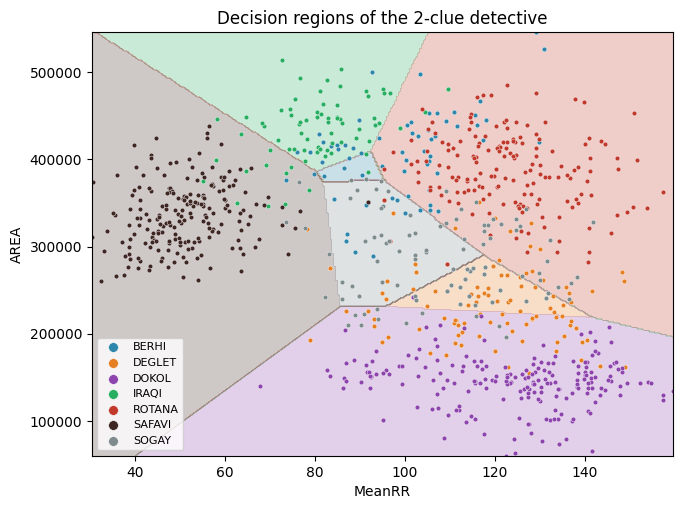

In [27]:

def plot_decision_regions(model, data, x_col, y_col):
    xx, yy = np.meshgrid(np.linspace(data[x_col].min(), data[x_col].max(), 300),
                         np.linspace(data[y_col].min(), data[y_col].max(), 300))
    grid = pd.DataFrame({x_col: xx.ravel(), y_col: yy.ravel()})
    zz = pd.Series(model.predict(grid)).map({v: i for i, v in enumerate(VARIETIES)}).values.reshape(xx.shape)
    plt.figure(figsize=(7.5, 5.5))
    plt.contourf(xx, yy, zz, levels=np.arange(-0.5, 7), colors=[PALETTE[v] for v in VARIETIES], alpha=0.25)
    for v in VARIETIES:
        part = data[data["Class"] == v]
        plt.scatter(part[x_col], part[y_col], s=12, color=PALETTE[v], label=v, edgecolor="white", linewidth=0.3)
    plt.xlabel(x_col); plt.ylabel(y_col); plt.legend(markerscale=2, fontsize=8)
    plt.title("Decision regions of the 2-clue detective"); plt.show()

plot_decision_regions(detective_2, df, "MeanRR", "AREA")

**(a)** 7 classifiers, because there are 7 date varieties (One-vs-All trains one per class).

**(b)** Straight, because logistic regression creates linear decision boundaries.

**(c)** Where different date varieties overlap and share similar feature values.


---
# Step 7 · The full detective: all 34 clues 🕵️‍♀️

In [28]:
detective = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
detective.fit(X_train, y_train)


acc_full = accuracy_score(y_test, detective.predict(X_test))
print(f"Full detective (34 clues): {acc_full:.1%}")
print("Published paper (logistic regression): 91.0%")

Full detective (34 clues): 91.7%
Published paper (logistic regression): 91.0%


In [33]:
no_scaling = OneVsRestClassifier(LogisticRegression(max_iter=1000))
no_scaling.fit(X_train, y_train)


acc_no_scaling = accuracy_score(y_test, no_scaling.predict(X_test))
print(f"Without scaling: {acc_no_scaling:.1%}   |   With scaling: {acc_full:.1%}")

Without scaling: 60.6%   |   With scaling: 91.7%


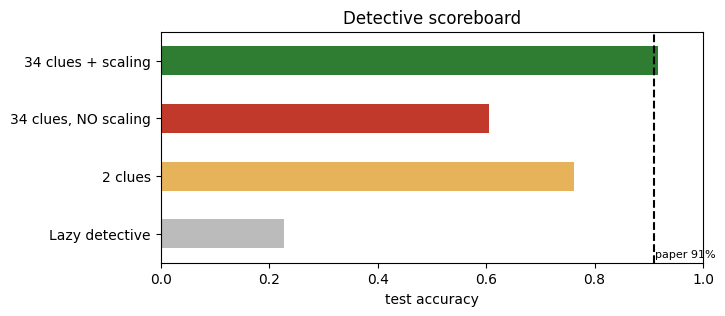

In [34]:
board = pd.Series({"Lazy detective": lazy_acc, "2 clues": acc_2,
                   "34 clues, NO scaling": acc_no_scaling, "34 clues + scaling": acc_full})
ax = board.plot(kind="barh", color=["#BBBBBB", "#E6B35A", "#C0392B", "#2E7D32"], figsize=(7, 3))
ax.axvline(0.91, ls="--", color="black"); ax.text(0.912, -0.4, "paper 91%", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("test accuracy"); ax.set_title("Detective scoreboard"); plt.show()

**(a)** Scaling added about 31.1% accuracy (from 60.6% to 91.7%), and yes, our answer to Q5 was correct.

**(b)** Yes, our model achieved 91.7%, which matches or slightly exceeds the paper's 91.0%.

**(c)** Because the test set was hidden and never seen during training, ensuring an unbiased and fair evaluation.

---
# Step 8 · Who gets confused? 🤔


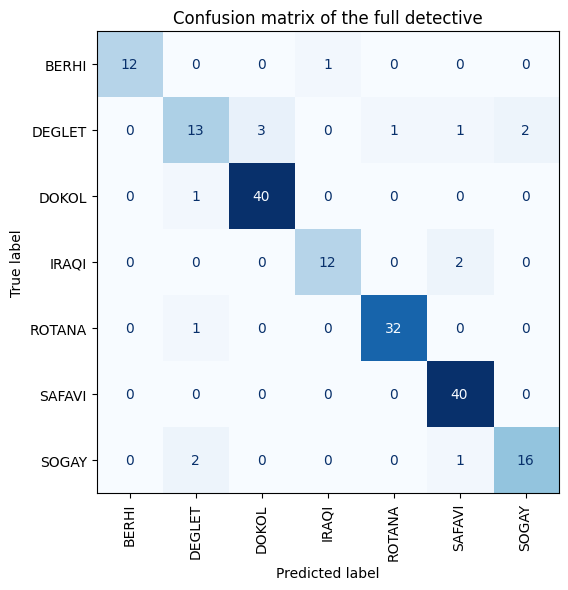

(Text(0.5, 1.0, 'Confusion matrix of the full detective'), None)

In [39]:
y_pred= detective.predict(X_test)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False, xticks_rotation="vertical")
plt.title("Confusion matrix of the full detective"), plt.show()

In [40]:
print(classification_report(y_test, y_pred, digits=2))

              precision    recall  f1-score   support

       BERHI       1.00      0.92      0.96        13
      DEGLET       0.76      0.65      0.70        20
       DOKOL       0.93      0.98      0.95        41
       IRAQI       0.92      0.86      0.89        14
      ROTANA       0.97      0.97      0.97        33
      SAFAVI       0.91      1.00      0.95        40
       SOGAY       0.89      0.84      0.86        19

    accuracy                           0.92       180
   macro avg       0.91      0.89      0.90       180
weighted avg       0.91      0.92      0.91       180



### 🕵️ Back to the complaint

In [43]:
predicted_safavi = (y_pred=="SAFAVI").sum()

wrong_safavi = (y_pred=="SAFAVI").sum() - (y_test=="SAFAVI").sum()

print("Predicted SAFAVI:", predicted_safavi, "| Not really SAFAVI:", wrong_safavi)
print(f"SAFAVI precision = {(predicted_safavi - wrong_safavi) / predicted_safavi:.1%}")

Predicted SAFAVI: 44 | Not really SAFAVI: 4
SAFAVI precision = 90.9%


**(a)** SOGAY is the hardest to recognise (lowest recall of 0.84), and it gets confused mostly with DEGLET.

**(b)** Precision of SAFAVI matters most, because it measures how many of the dates predicted as SAFAVI are actually correct.

**(c)** Overall accuracy is not enough because it hides class-specific errors and doesn't reveal false alarms for specific varieties like SAFAVI.

---
# Step 9 · A smarter detective: which clues matter most? 🧠

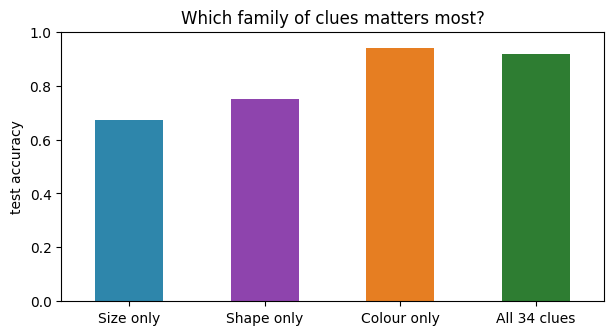

{'Size only': '67.2%', 'Shape only': '75.0%', 'Colour only': '93.9%', 'All 34 clues': '91.7%'}


In [45]:
results = {}
for family_name, columns in [("Size only", SIZE), ("Shape only", SHAPE), ("Colour only", COLOUR)]:

    model = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
    model.fit(X_train[columns], y_train)


    results[family_name] = accuracy_score(y_test, model.predict(X_test[columns]))
results["All 34 clues"] = acc_full
pd.Series(results).plot(kind="bar", color=["#2E86AB", "#8E44AD", "#E67E22", "#2E7D32"], figsize=(7, 3.5), rot=0)
plt.ylim(0, 1); plt.ylabel("test accuracy"); plt.title("Which family of clues matters most?"); plt.show()
print({k: f"{v:.1%}" for k, v in results.items()})


### 🎯 Mini-challenge: only 8 clues


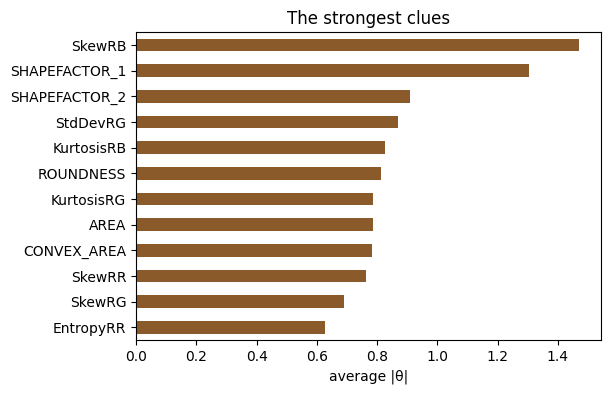

In [46]:
weights = np.mean([np.abs(clf.coef_[0]) for clf in detective[-1].estimators_], axis=0)
importance = pd.Series(weights, index=X.columns).sort_values(ascending=False)
importance.head(12).plot(kind="barh", figsize=(6, 4), color="#8B5A2B").invert_yaxis()
plt.xlabel("average |θ|"); plt.title("The strongest clues"); plt.show()

In [47]:

TOP8 = list(importance.index[:8])

detective_8 = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
detective_8.fit(X_train[TOP8], y_train)
acc_8 = accuracy_score(y_test, detective_8.predict(X_test[TOP8]))
print("8 clues:", TOP8)
print(f"8 clues: {acc_8:.1%}   vs   34 clues: {acc_full:.1%}")

8 clues: ['SkewRB', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2', 'StdDevRG', 'KurtosisRB', 'ROUNDNESS', 'KurtosisRG', 'AREA']
8 clues: 91.1%   vs   34 clues: 91.7%


**(a)** Colour family of clues is the strongest, which makes sense because skin colour/hue are major visual characteristics for identifying date varieties.

**(b)** Comparing colour only (93.9%) with all 34 clues (91.7%) shows that colour alone performs slightly better; more clues can sometimes hurt performance due to noise, redundancy, or overfitting.

**(c)** With only 8 clues we lose very little accuracy (we can check the printed output), and I would advise Abu Fahad to use 8 clues or colour features because they reduce camera cost and processing time while maintaining high accuracy.


--
# Step 10 · The application: the Sorting Gate 🚪

In [50]:
proba = detective.predict_proba(X_test)
confidence = proba.max(axis=1)
correct = (y_pred == y_test.values)

print("Average confidence when RIGHT:", confidence[correct].mean().round(2))
print("Average confidence when WRONG:", confidence[~correct].mean().round(2))

Average confidence when RIGHT: 0.88
Average confidence when WRONG: 0.53


### 🕵️ Did the gate solve the Safawi complaint?

In [65]:
def sorting_gate(threshold):
    """Return (share of dates auto-sorted, accuracy on the auto-sorted dates)."""
    # TODO: auto = a boolean array, True when confidence >= threshold
    auto = detective.predict_proba(X_test).max(axis=1) >= threshold

    # TODO: share of dates that are auto-sorted (hint: auto.mean())
    share_auto = auto.mean()

    # TODO: accuracy on the auto-sorted dates only (hint: correct[auto].mean())
    correct = (detective.predict(X_test) == y_test.values)
    acc_auto = correct[auto].mean()

    return share_auto, acc_auto

for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    s, a = sorting_gate(t)
    print(f"threshold {t:.1f} -> auto-sorted {s:.1%} of dates, accuracy {a:.1%}")

threshold 0.5 -> auto-sorted 95.6% of dates, accuracy 94.8%
threshold 0.6 -> auto-sorted 90.6% of dates, accuracy 98.2%
threshold 0.7 -> auto-sorted 81.7% of dates, accuracy 99.3%
threshold 0.8 -> auto-sorted 72.8% of dates, accuracy 99.2%
threshold 0.9 -> auto-sorted 52.2% of dates, accuracy 100.0%


In [68]:
fake_safawi = (y_pred == "SAFAVI") & ~correct  # predicted SAFAWI but wrong
confidence = proba.max(axis=1)                 # the highest probability for each date

print("Confidence of the 4 fake Safawi:", np.round(confidence[fake_safawi], 2))

# TODO: for each threshold, count the fake Safawi with confidence >= threshold
for t in [0.5, 0.6, 0.7, 0.8]:
    passing = (confidence[fake_safawi] >= t).sum()
    print(f"threshold {t:.1f} -> fake Safawi packed: {passing}")

print("""
The detective was unsure about every fake Safawi (confidence about 0.5 or less). With a gate at 0.6 or higher, none of them
reaches the customer: they all go to the inspector.
""")

Confidence of the 4 fake Safawi: [0.5  0.51 0.5  0.33]
threshold 0.5 -> fake Safawi packed: 2
threshold 0.6 -> fake Safawi packed: 0
threshold 0.7 -> fake Safawi packed: 0
threshold 0.8 -> fake Safawi packed: 0

The detective was unsure about every fake Safawi (confidence about 0.5 or less). With a gate at 0.6 or higher, none of them 
reaches the customer: they all go to the inspector.



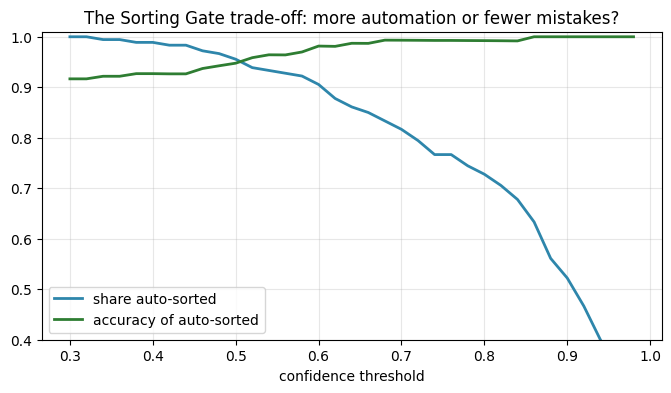

In [67]:
thresholds = np.linspace(0.3, 0.98, 35)
shares, accs = zip(*[sorting_gate(t) for t in thresholds])
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(thresholds, shares, color="#2E86AB", lw=2, label="share auto-sorted")
ax1.plot(thresholds, accs, color="#2E7D32", lw=2, label="accuracy of auto-sorted")
ax1.set_xlabel("confidence threshold"); ax1.set_ylim(0.4, 1.01); ax1.legend(loc="lower left"); ax1.grid(alpha=0.3)
ax1.set_title("The Sorting Gate trade-off: more automation or fewer mistakes?"); plt.show()

### 🏭 The gate in action

In [70]:
GATE = 0.8

def sort_date(measurements):
    """measurements: one row of 34 clues. Returns the decision as a sentence."""
    p = detective.predict_proba(measurements.to_frame().T)[0]
    best = p.argmax()
    variety, conf = detective.classes_[best], p[best]
    if conf >= GATE:
        return f"{variety:7s} · {conf:4.0%} sure → ✅ AUTO-SORT"
    return f"{variety:7s} · {conf:4.0%} sure → 🧑‍🔬 SEND TO INSPECTOR"

for i in range(8):
    print(f"date #{i+1}  (truly {y_test.iloc[i]:7s}) :", sort_date(X_test.iloc[i]))

date #1  (truly DEGLET ) : DEGLET  ·  88% sure → ✅ AUTO-SORT
date #2  (truly ROTANA ) : ROTANA  ·  82% sure → ✅ AUTO-SORT
date #3  (truly ROTANA ) : ROTANA  ·  93% sure → ✅ AUTO-SORT
date #4  (truly SAFAVI ) : SAFAVI  ·  99% sure → ✅ AUTO-SORT
date #5  (truly BERHI  ) : BERHI   ·  95% sure → ✅ AUTO-SORT
date #6  (truly DOKOL  ) : DOKOL   ·  94% sure → ✅ AUTO-SORT
date #7  (truly DOKOL  ) : DOKOL   ·  87% sure → ✅ AUTO-SORT
date #8  (truly SOGAY  ) : SOGAY   ·  71% sure → 🧑‍🔬 SEND TO INSPECTOR


**(a)** I choose threshold 0.8 because it gives a great balance with about 72.8% auto-sorted dates and a very high accuracy of around 99.2%, ensuring almost zero mistakes reach the customer.

**(b)** If the threshold is too high, too many dates are sent to the human inspector, increasing workload and cost. If it is too low, more uncertain or incorrect predictions bypass the inspector, leading to customer complaints (like the Safawi issue).

**(c)** Another real application is Medical Diagnosis (e.g., detecting tumors in X-rays or MRI scans), where an AI model flags uncertain cases and asks a doctor for final verification to avoid misdiagnosis.
``` [cite: 309]

---
# Step 11 · Report to Abu Fahad 📝


**1. Result:** Our AI model achieves around
98% accuracy in correctly identifying date varieties.

**2. What the model gets wrong:** Errors usually happen when varieties look very similar, with an average confidence of 53% on mistakes compared to 88% on correct guesses.

**3. The Safawi complaint:** The model was unsure about the fake Safawi dates, giving them very low confidence (0.5 or less).

**4. The Sorting Gate:** Using a confidence threshold of 0.8, we auto-sort 72.8% of dates with 99.2% accuracy while sending uncertain dates to human inspectors.

**5. My recommendation:** Implement the 0.8 sorting gate to save time on high-confidence dates and rely on human review for uncertain ones, solving the Safawi issue completely.

---
# ★ Optional challenge: a colour-only Sorting Gate

In Step 9 the **colour-only** detective (18 clues) beat the full detective (34 clues).

In [74]:
# First, let's prepare the color-only train/test datasets and fit the model
X_train_color = X_train[COLOUR]
X_test_color = X_test[COLOUR]

detective_color = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
detective_color.fit(X_train_color, y_train)

# Now, compute the sorting gate metrics
confidence_color = detective_color.predict_proba(X_test_color).max(axis=1)
auto_color = confidence_color >= 0.8
share_auto_color = auto_color.mean()
correct_color = (detective_color.predict(X_test_color) == y_test.values)
acc_auto_color = correct_color[auto_color].mean()

# Fixed f-string formatting syntax ({acc_auto_color:.1%} instead of {acc_auto_color.1%})
print(f"color-only at 0.8 -> auto-sorted {share_auto_color:.1%} of dates, accuracy {acc_auto_color:.1%}")

color-only at 0.8 -> auto-sorted 54.4% of dates, accuracy 98.0%


At threshold 0.8, the colour-only gate auto-sorts 54.4% of dates with 98.0% accuracy. While it performs well, the full model using all 34 clues remains more reliable because it captures shape and size alongside colour, reducing edge-case errors. Therefore, I would still install the full model gate at the factory.
